#1.Dataset Selection

###imports

In [1]:
# Install the 'requests' library for making HTTP requests
!pip install requests

# Import necessary libraries
import requests  # For sending HTTP requests
import pandas as pd  # For data manipulation and analysis
import time  # For time-related functions (e.g., delays)
import ast  # For parsing strings into Python objects
import numpy as np  # For numerical operations
import matplotlib.pyplot as plt  # For creating visualizations (plots)
from matplotlib_venn import venn3
import seaborn as sns  # For statistical data visualization
import re  # For regular expression operations
import datetime



###API Fetch Functions

In [ ]:
def fetch_openalex_cursor(cursor="*", per_page=200):
    """
    Fetch one page of results from the OpenAlex API using cursor-based pagination.

    Parameters:
    cursor (str): The cursor to start fetching from. Default is "*" (first page).
    per_page (int): The number of results per page. Default is 200.

    Returns:
    dict: A dictionary containing the JSON response with the requested data, or None if there was an error.
    """
    url = f"https://api.openalex.org/works?per_page={per_page}&cursor={cursor}"

    try:
        response = requests.get(url)
        response.raise_for_status()  # Check if the request was successful
        return response.json()  # Return JSON response
    except Exception as e:
        print("Error:", e)  # Print error if request fails
        return None  # Return None if there's an error


###Parsing Function

In [ ]:
def parse_data(data):
    """
    Parse and extract relevant fields from OpenAlex API response data.

    Parameters:
    data (dict): JSON response containing a list of works under the 'results' key.

    Returns:
    list: A list of dictionaries with extracted and cleaned work information.
    """
    parsed_data = []

    for work in data['results']:
        work_info = {
            'id': work.get('id', '').split('/')[-1],  # Extract work ID
            'primary_topic': work.get('primary_topic', {}).get('display_name'),
            'publication_year': work.get('publication_year', ''),
            'source': ((work.get('primary_location') or {}).get('source') or {}).get('display_name', ''),
            'authorships': [author['author']['display_name'] for author in work.get('authorships', [])],
            'language': work.get('language', ''),
            'cited_by_count': work.get('cited_by_count', 0),
            'references_count': work.get('referenced_works_count', 0),
            'institution': list({
                inst.get('display_name')
                for author in work.get('authorships', [])
                for inst in author.get('institutions', [])
            }),
            'type': work.get('type', '')
        }
        parsed_data.append(work_info)

    return parsed_data


###Fetch Many Pages + Save CSV

In [ ]:
def fetch_and_save_cursor(total_rows=15000, per_page=200, outfile="openalex_15000.csv"):
    """
    Fetch multiple pages of OpenAlex works using cursor pagination and save them to a CSV file.

    Parameters:
    total_rows (int): Total number of records to fetch.
    per_page (int): Number of records per API request.
    outfile (str): Output CSV file name.

    Returns:
    pandas.DataFrame: DataFrame containing all fetched and parsed records.
    """
    all_data = []
    cursor = "*"
    pages_needed = total_rows // per_page

    print(f"Fetching {total_rows} works via cursor pagination...")

    for page in range(pages_needed):
        print(f"Fetching page {page+1}/{pages_needed}  (cursor={cursor})")

        data = fetch_openalex_cursor(cursor, per_page)
        if data is None:
            print("Stopping due to error.")
            break

        parsed = parse_data(data)
        all_data.extend(parsed)

        # Update cursor for next page
        cursor = data['meta']['next_cursor']

        time.sleep(1)  # avoid hitting rate limits

    df = pd.DataFrame(all_data)
    df.to_csv(outfile, index=False)

    print(f"\nSaved {len(df)} rows to {outfile}")
    return df


###Run

In [ ]:
# Fetch data from OpenAlex, save it to a CSV file, and load it into a DataFrame
df = fetch_and_save_cursor()

# Display the first few rows of the DataFrame
df.head()


Fetching 15000 works via cursor pagination...
Fetching page 1/75  (cursor=*)
Fetching page 2/75  (cursor=IlsxMDAuMCwgMzM5NzQsICdodHRwczovL29wZW5hbGV4Lm9yZy9XMjAzNzM3NzAyNSddIg==)
Fetching page 3/75  (cursor=IlsxMDAuMCwgMjM2NjUsICdodHRwczovL29wZW5hbGV4Lm9yZy9XMjEyNTA1NTI1OSddIg==)
Fetching page 4/75  (cursor=IlsxMDAuMCwgMTk1MzksICdodHRwczovL29wZW5hbGV4Lm9yZy9XMjQxMjI0NzEzMyddIg==)
Fetching page 5/75  (cursor=IlsxMDAuMCwgMTY4MDUsICdodHRwczovL29wZW5hbGV4Lm9yZy9XMjAxMTMwMzM5NyddIg==)
Fetching page 6/75  (cursor=IlsxMDAuMCwgMTUwMTcsICdodHRwczovL29wZW5hbGV4Lm9yZy9XMTU5NTQ5ODczMyddIg==)
Fetching page 7/75  (cursor=IlsxMDAuMCwgMTM1NzEsICdodHRwczovL29wZW5hbGV4Lm9yZy9XMjA0NTIwNDc4MSddIg==)
Fetching page 8/75  (cursor=IlsxMDAuMCwgMTI1ODQsICdodHRwczovL29wZW5hbGV4Lm9yZy9XMjU5NzA3MDc5MiddIg==)
Fetching page 9/75  (cursor=IlsxMDAuMCwgMTE1ODYsICdodHRwczovL29wZW5hbGV4Lm9yZy9XMTk5MzI0MzU5MiddIg==)
Fetching page 10/75  (cursor=IlsxMDAuMCwgMTA4NjgsICdodHRwczovL29wZW5hbGV4Lm9yZy9XMzAyMjgwODI5MSddIg==)
Fetc

,id,primary_topic,publication_year,source,authorships,language,cited_by_count,references_count,institution,type
0,W3038568908,Magnetic confinement fusion research,2020,Plasma and Fusion Research,[M. Shoji],en,801215,8,"[National Institutes of Natural Sciences, Nati...",article
1,W1775749144,Glycosylation and Glycoproteins Research,1951,Journal of Biological Chemistry,"[OliverH. Lowry, NiraJ. Rosebrough, A. Farr, R...",zu,316796,20,[Washington University in St. Louis],article
2,W2100837269,Bacteriophages and microbial interactions,1970,Nature,[Ulrich K. Laemmli],en,250622,21,[MRC Laboratory of Molecular Biology],article
3,W2128635872,Meat and Animal Product Quality,1976,Analytical Biochemistry,[Mark A. Bradford],en,225179,19,[University of Georgia],article
4,W2194775991,Advanced Neural Network Applications,2016,,"[Kaiming He, Xiangyu Zhang, Shaoqing Ren, Jian...",en,208735,81,[Microsoft Research (United Kingdom)],article


##load dataset to df

In [86]:
# Load the previously saved CSV file into a pandas DataFrame.
df = pd.read_csv('openalex_15000.csv')

#2.Data Cleaning and Preparation

###Handle missing values

In [87]:
def clean_openalex_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    """
    Clean and standardize an OpenAlex DataFrame.

    - Converts string representations of lists to actual lists
    - Removes rows with missing language
    - Replaces missing or empty authorship and institution values
    - Fills missing or empty source values

    Parameters:
    df (pd.DataFrame): Raw OpenAlex DataFrame.

    Returns:
    pd.DataFrame: Cleaned DataFrame.
    """
    def safe_eval_list(val):
        try:
            return ast.literal_eval(val)
        except:
            return val

    df = df.copy()

    # Convert string representations to lists
    df['authorships'] = df['authorships'].apply(safe_eval_list)
    df['institution'] = df['institution'].apply(safe_eval_list)

    # Remove rows where language is missing or empty
    df = df[df['language'].notna() & (df['language'] != '')]

    # Replace empty or missing authorships with ['UnKnown']
    def fix_authorships(val):
        if val is None or (isinstance(val, float) and pd.isna(val)):
            return ['UnKnown']
        elif isinstance(val, str):
            if val.strip() == '' or val == '[]':
                return ['UnKnown']
        elif isinstance(val, list):
            if len(val) == 0:
                return ['UnKnown']
        return val

    df['authorships'] = df['authorships'].apply(fix_authorships)

    # Replace empty or missing institutions with ['UnKnown']
    def fix_institution(val):
        if val is None or (isinstance(val, float) and pd.isna(val)):
            return ['UnKnown']
        elif isinstance(val, str):
            if val.strip() == '' or val == '[]':
                return ['UnKnown']
        elif isinstance(val, list):
            if len(val) == 0:
                return ['UnKnown']
        return val

    df['institution'] = df['institution'].apply(fix_institution)

    # Replace empty or missing source values
    df['source'] = df['source'].fillna('NoSource')
    df['source'] = df['source'].replace('', 'NoSource')

    return df


# Call cleaning function
df = clean_openalex_dataframe(df)

print("Rows after cleaning:", len(df))


Rows after cleaning: 14993


###Handle duplicates and irrelevant data

In [88]:
# A function to remove duplicate entries based on the 'id' column
def remove_duplicate_ids(df: pd.DataFrame) -> pd.DataFrame:
    """
    Remove rows with duplicate IDs from the DataFrame.

    Parameters:
    df (pd.DataFrame): Input DataFrame containing an 'id' column.

    Returns:
    pd.DataFrame: DataFrame with only unique IDs retained.
    """
    df = df.copy()
    return df[~df['id'].duplicated(keep=False)]


# Call function
df = remove_duplicate_ids(df)

print("Rows after removing duplicate IDs:", len(df))


Rows after removing duplicate IDs: 14993


###Identify outliers

In [89]:
# Identify outliers in numerical columns:
# number of citations and number of references
numerical_cols = [
    'cited_by_count',
    'references_count'
]

for col in numerical_cols:
    # Calculate interquartile range (IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    # Define outlier boundaries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count outliers
    outlier_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    print(f"{col}:")
    print(f"  Lower bound = {lower_bound:.2f}")
    print(f"  Upper bound = {upper_bound:.2f}")
    print(f"  Outliers detected = {outlier_count}\n")


cited_by_count:
  Lower bound = -1044.50
  Upper bound = 12151.50
  Outliers detected = 1471

references_count:
  Lower bound = -91.50
  Upper bound = 152.50
  Outliers detected = 1413



###Handle outliers

In [90]:
# Add an outlier flag column for each numerical feature
# Mark 1 if the value is an upper-bound outlier, 0 otherwise
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    # Define upper bound for outliers
    upper_bound = Q3 + 1.5 * IQR

    # Create binary outlier indicator column
    df[f'{col}_outlier'] = (df[col] > upper_bound).astype(int)


#3.Data Transformation

In [91]:
def add_author_and_institution_counts_inplace(df: pd.DataFrame):
    """
    Adds 'num_authors' and 'num_institutions' columns to the DataFrame.
    Counts the number of authors and institutions, treating 'UnKnown' as NaN for counting purposes.
    Modifies the DataFrame in place.
    """
    def count_authors(val):
        if isinstance(val, list) and len(val) == 1 and val[0] == 'UnKnown':
            return np.nan
        if isinstance(val, list):
            return len(val)
        return np.nan

    def count_institutions(val):
        if isinstance(val, list) and len(val) == 1 and val[0] == 'UnKnown':
            return np.nan
        if isinstance(val, list):
            return len(val)
        return np.nan

    # Apply counting functions to create new feature columns
    df['num_authors'] = df['authorships'].apply(count_authors)
    df['num_institutions'] = df['institution'].apply(count_institutions)


# Call the function to add new columns
add_author_and_institution_counts_inplace(df)

print("Added 2 features: num_authors and num_institutions")


Added 2 features: num_authors and num_institutions


#4.1.Data Exploration with outliers

###Basic overview

In [92]:
# Display the number of rows and columns in the DataFrame
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Display summary of DataFrame including column names, non-null counts, and data types
df.info()


Rows: 14993
Columns: 14
<class 'pandas.core.frame.DataFrame'>
Index: 14993 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        14993 non-null  object 
 1   primary_topic             14993 non-null  object 
 2   publication_year          14993 non-null  int64  
 3   source                    14993 non-null  object 
 4   authorships               14993 non-null  object 
 5   language                  14993 non-null  object 
 6   cited_by_count            14993 non-null  int64  
 7   references_count          14993 non-null  int64  
 8   institution               14993 non-null  object 
 9   type                      14993 non-null  object 
 10  cited_by_count_outlier    14993 non-null  int64  
 11  references_count_outlier  14993 non-null  int64  
 12  num_authors               14779 non-null  float64
 13  num_institutions          10728 non-null  

##Handling Dtype

In [93]:
# 1. Clean the 'institution' column (and any others containing lists)
# This joins ['Harvard', 'MIT'] into 'Harvard, MIT'
def clean_list_col(val):
    if isinstance(val, list):
        return ", ".join(map(str, val))
    return val

# List of columns that might contain list data
cols_to_fix = ['institution', 'source', 'primary_topic']

for col in cols_to_fix:
    df[col] = df[col].apply(clean_list_col)

# 2. Now perform the type conversions safely
df['id'] = df['id'].astype('string')

categorical_cols = ['primary_topic', 'source', 'language', 'institution', 'type']
for col in categorical_cols:
    df[col] = df[col].astype('category')

# 3. Handle the numeric columns with missing values
df['num_authors'] = df['num_authors'].astype('Int64')
df['num_institutions'] = df['num_institutions'].astype('Int64')

# 4. converting it to 'string' ensures it is no longer an 'object' type.
df['authorships'] = df['authorships'].astype('string')

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14993 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   id                        14993 non-null  string  
 1   primary_topic             14993 non-null  category
 2   publication_year          14993 non-null  int64   
 3   source                    14993 non-null  category
 4   authorships               14993 non-null  string  
 5   language                  14993 non-null  category
 6   cited_by_count            14993 non-null  int64   
 7   references_count          14993 non-null  int64   
 8   institution               14993 non-null  category
 9   type                      14993 non-null  category
 10  cited_by_count_outlier    14993 non-null  int64   
 11  references_count_outlier  14993 non-null  int64   
 12  num_authors               14779 non-null  Int64   
 13  num_institutions          10728 non-null  Int64   


##Summary statistics

In [94]:
# Compute summary statistics using lambda functions for percentiles
summary = df[['cited_by_count', 'references_count', 'publication_year', 'num_authors', 'num_institutions']].agg([
    'mean',
    'median',
    'min',
    'max',
    lambda x: x.quantile(0.25),
    lambda x: x.quantile(0.75)
])

# Rename the rows so they look clean
summary.index = ['mean', 'median', 'min', 'max', '25%', '75%']

# Format to remove scientific notation (e+)
summary.style.format("{:.2f}")

,cited_by_count,references_count,publication_year,num_authors,num_institutions
mean,7207.01,63.04,1996.11,5.50,3.39
median,4905.00,26.00,2000.00,2.00,2.00
min,3327.00,0.00,1739.00,1.00,1.00
max,801215.00,8095.00,2025.00,100.00,121.00
25%,3904.00,0.00,1988.00,1.00,1.00
75%,7203.00,61.00,2009.00,4.00,3.00


##Distribution plots

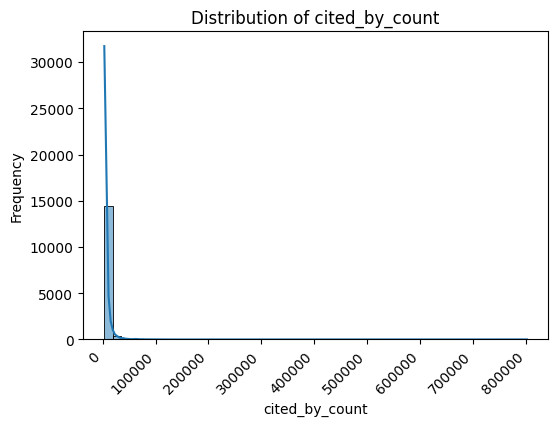

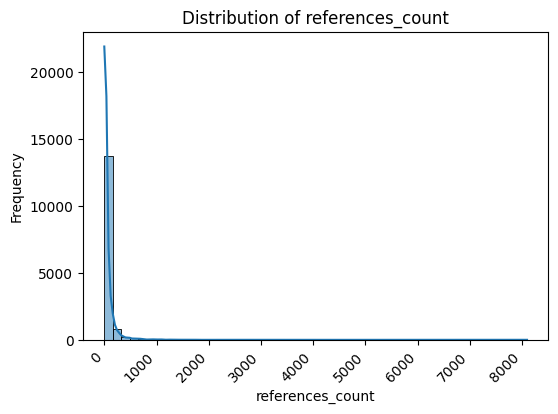

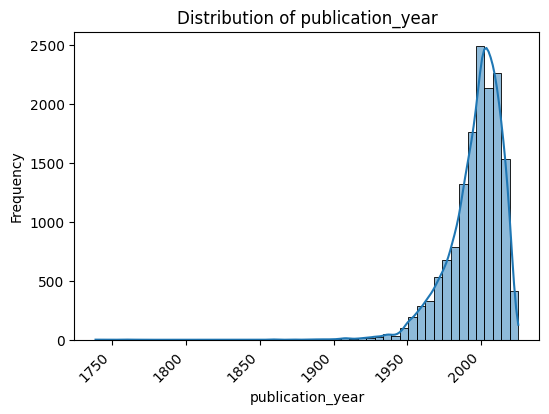

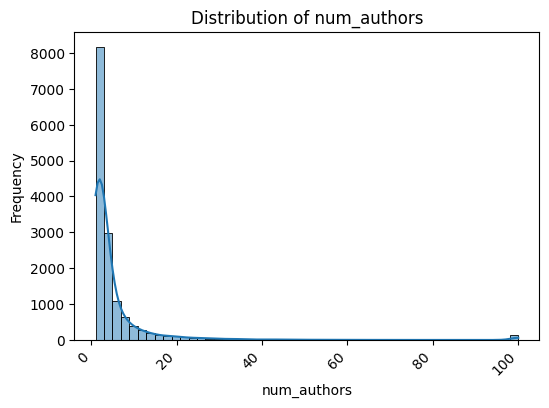

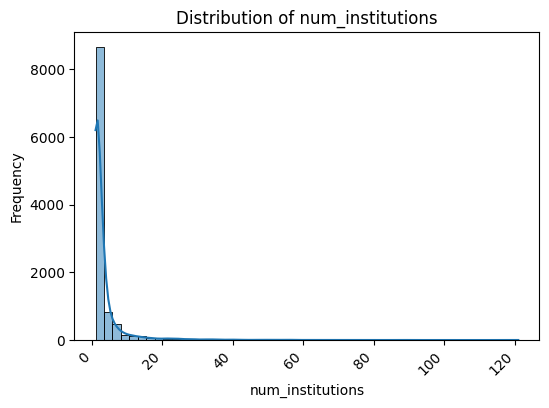

In [95]:
# Plot distributions of numerical columns using histograms with KDE
numerical_cols = [
    'cited_by_count',
    'references_count',
    'publication_year',
    'num_authors',
    'num_institutions'
]

for col in numerical_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(df[col].dropna(), bins=50, kde=True)  # Histogram with kernel density estimate
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.xticks(rotation=45, ha='right')
    plt.show()


##Bar plots

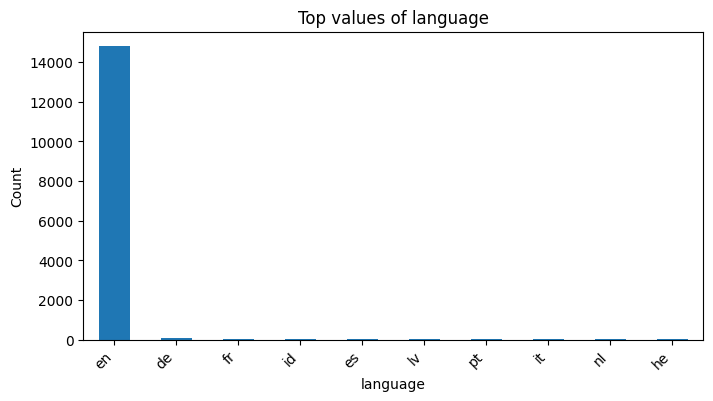

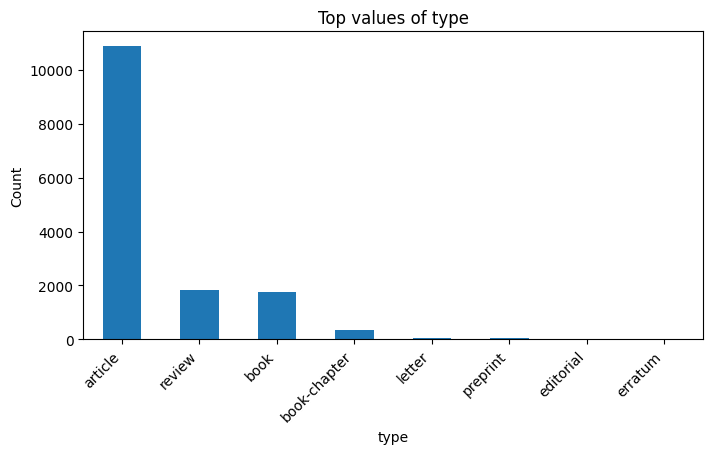

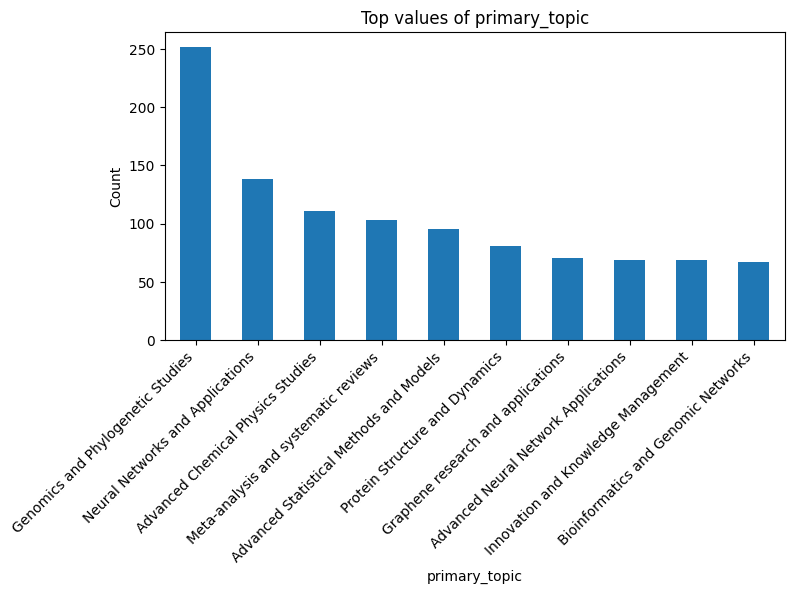

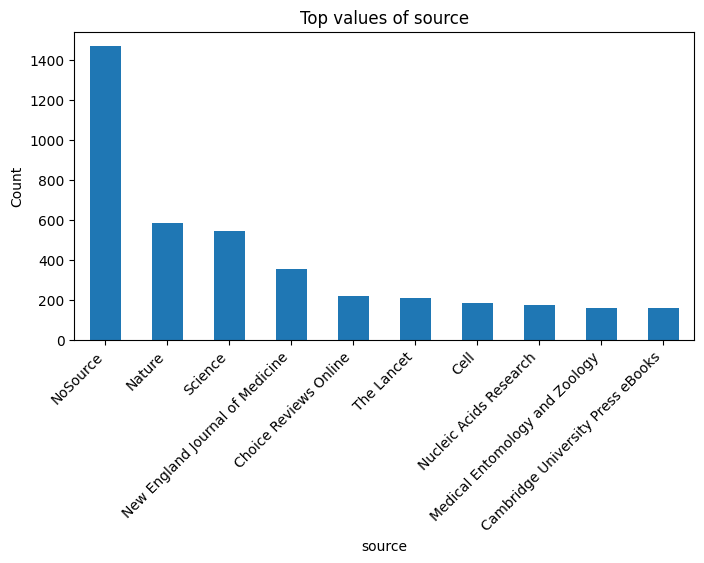

In [96]:
# Plot top 10 counts for categorical columns
categorical_cols = [
    'language',
    'type',
    'primary_topic',
    'source'
]

for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    df[col].value_counts().head(10).plot(kind='bar')  # Bar plot of top 10 values
    plt.title(f'Top values of {col}')
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.show()


##Simple relationship plots

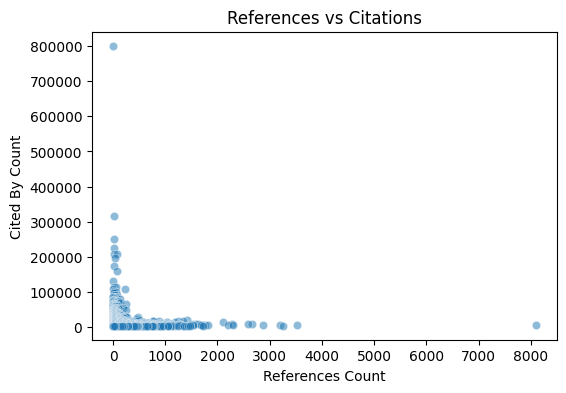

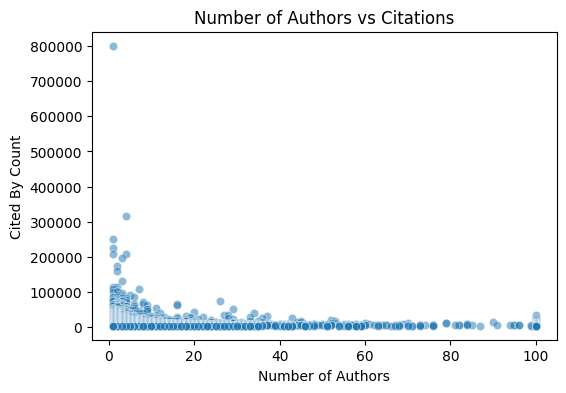

In [97]:
# Scatter plot: References count vs Citations
plt.figure(figsize=(6, 4))
sns.scatterplot(
    x=df['references_count'],
    y=df['cited_by_count'],
    alpha=0.5  # Set transparency for better visualization of dense points
)
plt.title('References vs Citations')
plt.xlabel('References Count')
plt.ylabel('Cited By Count')
plt.show()

# Scatter plot: Number of authors vs Citations
plt.figure(figsize=(6, 4))
sns.scatterplot(
    x=df['num_authors'],
    y=df['cited_by_count'],
    alpha=0.5
)
plt.title('Number of Authors vs Citations')
plt.xlabel('Number of Authors')
plt.ylabel('Cited By Count')
plt.show()


#4.2.Data Exploration without outliers

###Basic overview

In [98]:
# Filter out rows flagged as outliers for 'cited_by_count' and 'references_count'
df_plot = df[(df['cited_by_count_outlier'] == 0) & (df['references_count_outlier'] == 0)]

# Display the number of rows and columns after removing outliers
print("Rows without outliers:", len(df_plot))
print("Columns:", df_plot.shape[1])

# Display summary of the filtered DataFrame
df_plot.info()


Rows without outliers: 12173
Columns: 14
<class 'pandas.core.frame.DataFrame'>
Index: 12173 entries, 1472 to 14999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   id                        12173 non-null  string  
 1   primary_topic             12173 non-null  category
 2   publication_year          12173 non-null  int64   
 3   source                    12173 non-null  category
 4   authorships               12173 non-null  string  
 5   language                  12173 non-null  category
 6   cited_by_count            12173 non-null  int64   
 7   references_count          12173 non-null  int64   
 8   institution               12173 non-null  category
 9   type                      12173 non-null  category
 10  cited_by_count_outlier    12173 non-null  int64   
 11  references_count_outlier  12173 non-null  int64   
 12  num_authors               11997 non-null  Int64   
 13  num_ins

###Summary statistics

In [99]:
# Compute summary statistics for numerical columns in the filtered DataFrame (without outliers)
numerical_cols = [
    'cited_by_count',
    'references_count',
    'publication_year',
    'num_authors',
    'num_institutions'
]

df_plot[numerical_cols].describe()


,cited_by_count,references_count,publication_year,num_authors,num_institutions
count,12173.000000,12173.000000,12173.000000,11997.0,8490.0
mean,5368.823873,32.063008,1995.041485,5.139201,3.210483
std,2008.726209,36.508525,18.669748,10.8516,6.016027
min,3327.000000,0.000000,1739.000000,1.0,1.0
25%,3839.000000,0.000000,1987.000000,1.0,1.0
50%,4672.000000,22.000000,1999.000000,2.0,2.0
75%,6257.000000,48.000000,2008.000000,4.0,3.0
max,12146.000000,152.000000,2025.000000,100.0,100.0


###Distribution plots

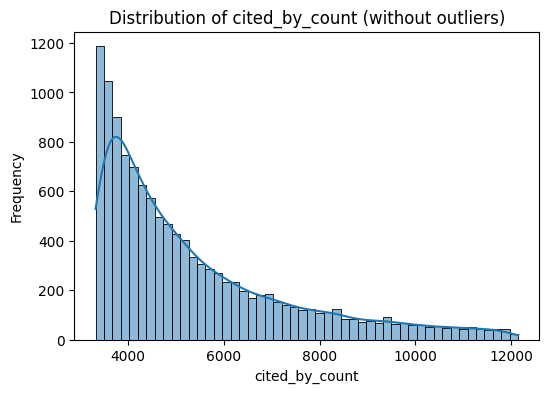

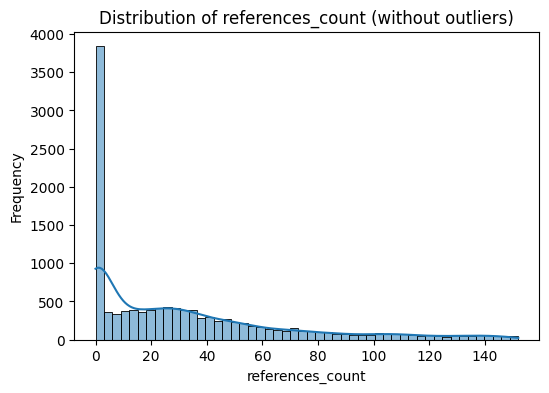

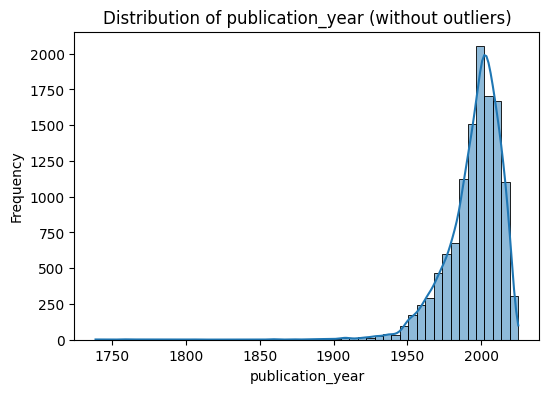

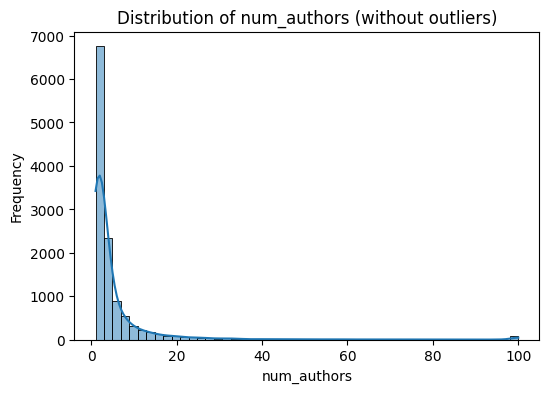

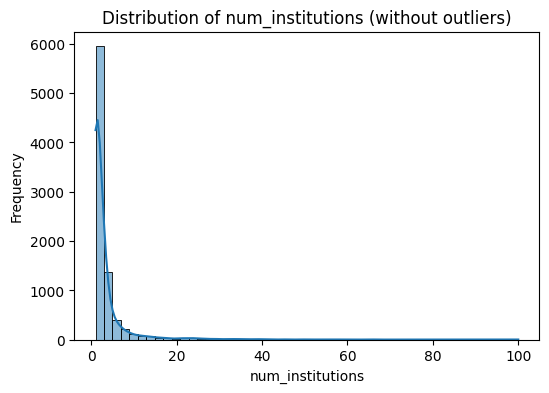

In [100]:
# Plot distributions of numerical columns in the filtered DataFrame (without outliers)
for col in numerical_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(df_plot[col].dropna(), bins=50, kde=True)  # Histogram with KDE
    plt.title(f'Distribution of {col} (without outliers)')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()


###Bar plots

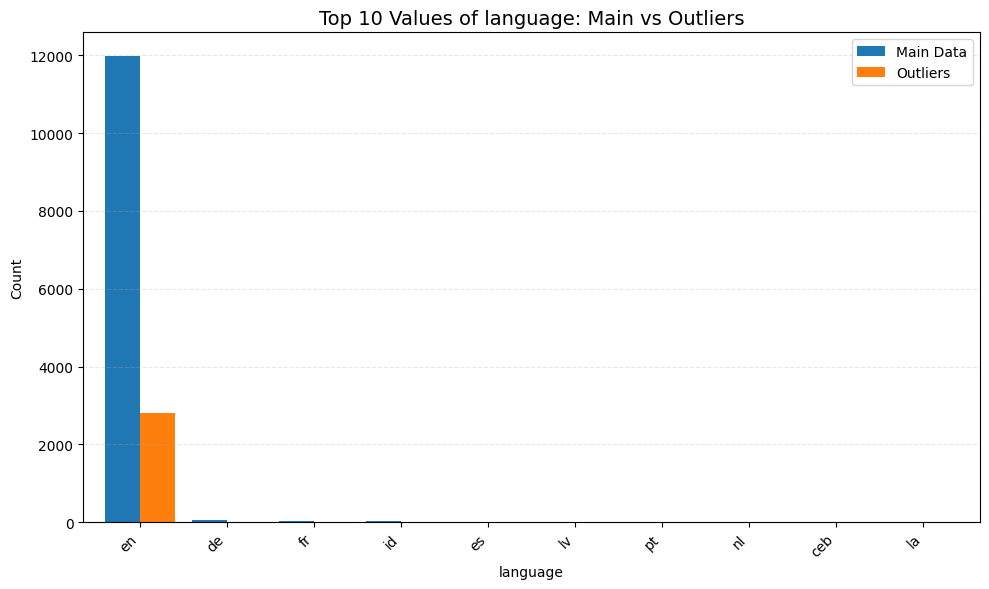

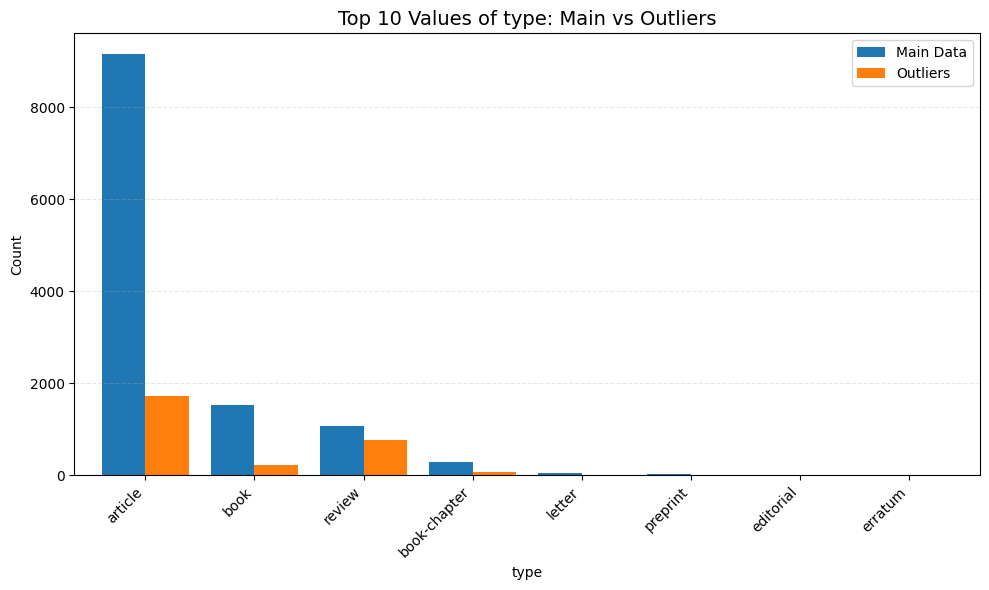

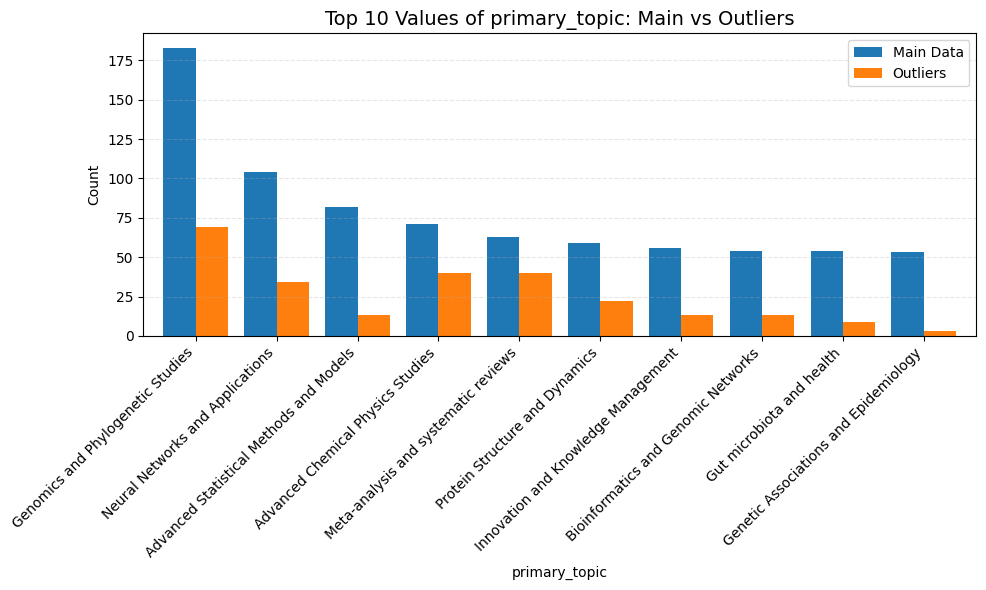

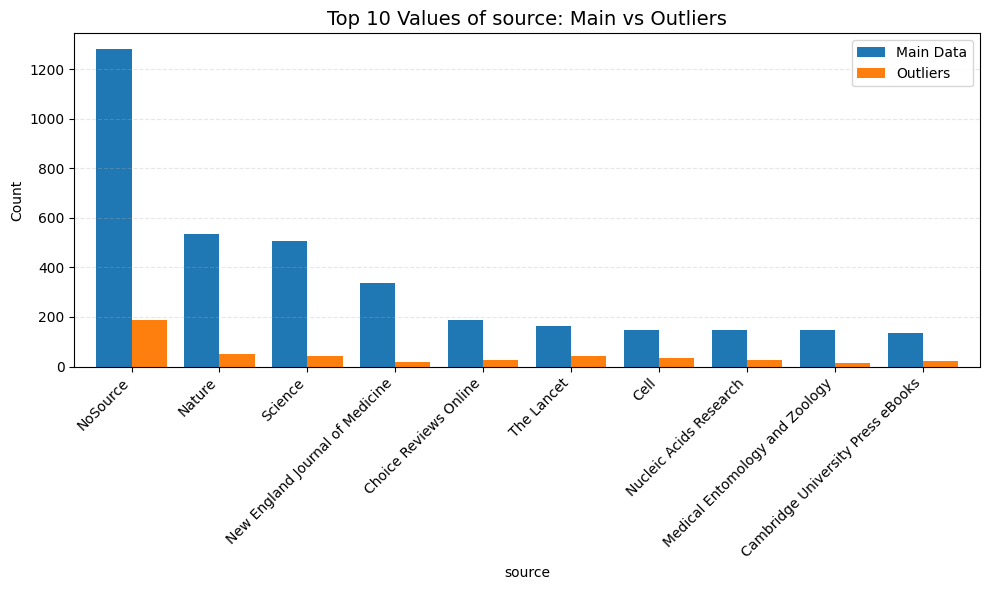

In [101]:
# Compare top 10 categorical values between main data and outliers
categorical_cols = ['language', 'type', 'primary_topic', 'source']
df_outliers = df[(df['cited_by_count_outlier'] == 1) | (df['references_count_outlier'] == 1)]

for col in categorical_cols:
    # Get value counts for main data and outliers
    main_counts = df_plot[col].value_counts()
    outlier_counts = df_outliers[col].value_counts()

    # Combine counts into a single DataFrame and fill missing values with 0
    combined_df = pd.DataFrame({
        'Main Data': main_counts,
        'Outliers': outlier_counts
    }).fillna(0)

    # Sort by main data frequency and take top 10
    combined_df = combined_df.sort_values(by='Main Data', ascending=False).head(10)

    # Clean index of non-ASCII characters to prevent font errors
    combined_df.index = [str(x).encode('ascii', 'ignore').decode('ascii') for x in combined_df.index]

    # Plot comparison bar chart
    ax = combined_df.plot(kind='bar', figsize=(10, 6), width=0.8)

    plt.title(f'Top 10 Values of {col}: Main vs Outliers', fontsize=14)
    plt.ylabel('Count')
    plt.xlabel(col)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()


###Simple relationship plots

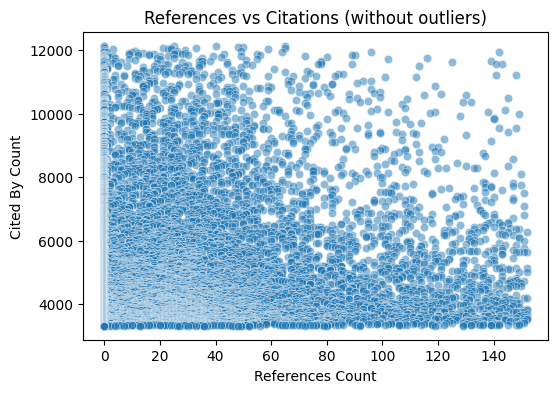

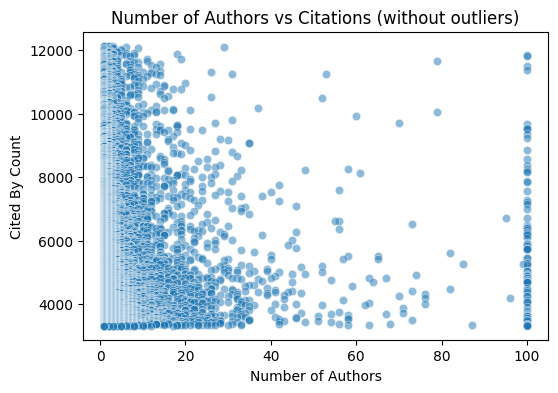

In [102]:
# Filter out outliers for plotting
df_plot = df[(df['cited_by_count_outlier'] == 0) & (df['references_count_outlier'] == 0)]

# Scatter plot: References count vs Citations (without outliers)
plt.figure(figsize=(6, 4))
sns.scatterplot(
    x=df_plot['references_count'],
    y=df_plot['cited_by_count'],
    alpha=0.5  # Transparency for dense points
)
plt.title('References vs Citations (without outliers)')
plt.xlabel('References Count')
plt.ylabel('Cited By Count')
plt.show()

# Scatter plot: Number of Authors vs Citations (without outliers)
plt.figure(figsize=(6, 4))
sns.scatterplot(
    x=df_plot['num_authors'],
    y=df_plot['cited_by_count'],
    alpha=0.5
)
plt.title('Number of Authors vs Citations (without outliers)')
plt.xlabel('Number of Authors')
plt.ylabel('Cited By Count')
plt.show()


###key findings

In [103]:
# Compare top categorical values between outliers and non-outliers
categorical_cols = ['language', 'type', 'primary_topic', 'source']

# Split the data into outliers and non-outliers
df_outliers = df[(df['cited_by_count_outlier'] == 1) | (df['references_count_outlier'] == 1)]
df_no_outliers = df[(df['cited_by_count_outlier'] == 0) & (df['references_count_outlier'] == 0)]

same_count = 0
total_cols = len(categorical_cols)

for col in categorical_cols:
    # Get value counts for both subsets
    out_counts = df_outliers[col].value_counts()
    no_out_counts = df_no_outliers[col].value_counts()

    # Determine top value for outliers
    if not out_counts.empty:
        top_out_val = out_counts.index[0]
        top_out_count = out_counts.iloc[0]
        if top_out_val == 'NoSource':
            if len(out_counts) > 1:
                next_top_val = out_counts.index[1]
                next_top_count = out_counts.iloc[1]
                top_out_val_text = f"NoSource (top), next max: {next_top_val} ({next_top_count})"
            else:
                top_out_val_text = "NoSource (top), no other values"
        else:
            top_out_val_text = f"{top_out_val} ({top_out_count})"
    else:
        top_out_val_text = "N/A"

    # Determine top value for non-outliers
    top_no_out_val = no_out_counts.index[0]
    top_no_out_count = no_out_counts.iloc[0]
    if top_no_out_val == 'NoSource':
        if len(no_out_counts) > 1:
            next_top_val_no = no_out_counts.index[1]
            next_top_count_no = no_out_counts.iloc[1]
            top_no_out_val_text = f"NoSource (top), next max: {next_top_val_no} ({next_top_count_no})"
        else:
            top_no_out_val_text = "NoSource (top), no other values"
    else:
        top_no_out_val_text = f"{top_no_out_val} ({top_no_out_count})"

    # Count matches ignoring 'NoSource'
    if top_out_val != 'NoSource' and top_out_val == top_no_out_val:
        same_count += 1

    # Print results
    print(f"=== {col} ===")
    print(f"Outliers    → Top: {top_out_val_text}")
    print(f"Non-outliers→ Top: {top_no_out_val_text}\n")

# Provide interpretation of outlier impact
if same_count == 0:
    text = "Outliers have heavily affected the top categorical values; none of the top values match."
elif same_count == total_cols:
    text = "Outliers did not affect the top categorical values; all top values are the same."
else:
    text = f"Outliers partially affected the results; {same_count} out of {total_cols} top values are the same."

print("=== Interpretation ===")
print(text)

=== language ===
Outliers    → Top: en (2802)
Non-outliers→ Top: en (11990)

=== type ===
Outliers    → Top: article (1732)
Non-outliers→ Top: article (9149)

=== primary_topic ===
Outliers    → Top: Genomics and Phylogenetic Studies (69)
Non-outliers→ Top: Genomics and Phylogenetic Studies (183)

=== source ===
Outliers    → Top: NoSource (top), next max: Chemical Reviews (93)
Non-outliers→ Top: NoSource (top), next max: Nature (534)

=== Interpretation ===
Outliers partially affected the results; 3 out of 4 top values are the same.


/tmp/ipython-input-668861045.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('type')              # Group by work type


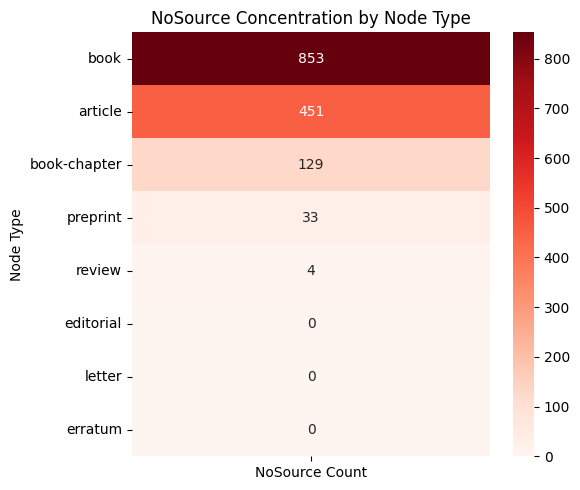

In [104]:
# Calculate the distribution of 'NoSource' entries across different 'type' categories
nosource_by_type = (
    df[df['source'] == 'NoSource']  # Filter entries where source is 'NoSource'
      .groupby('type')              # Group by work type
      .size()                       # Count occurrences
      .sort_values(ascending=False) # Sort in descending order
)

# Create a heatmap to visualize the concentration of 'NoSource' by work type
plt.figure(figsize=(6, 5))
sns.heatmap(
    nosource_by_type.to_frame(name='NoSource Count'),  # Convert to DataFrame for heatmap
    annot=True,    # Show count values
    fmt='d',       # Format annotation as integers
    cmap='Reds'    # Color scheme: shades of red
)

plt.title('NoSource Concentration by Node Type')
plt.ylabel('Node Type')
plt.xlabel('')
plt.tight_layout()
plt.show()


#4.3.Data Exploration three eras


##Setup and Time Period Categorization

In [105]:
# Categorize data into the three defined eras
def categorize_era(year):
    if year <= 1990:
        return 'Pre-Digital Era (<=1990)'
    elif 1991 <= year <= 2005:
        return 'Digital Transition (1991-2005)'
    else:
        return 'Open Access / AI Era (2006-2025)'

df['era'] = df['publication_year'].apply(categorize_era)

# Define the order for consistent plotting
era_order = ['Pre-Digital Era (<=1990)', 'Digital Transition (1991-2005)', 'Open Access / AI Era (2006-2025)']

##Citation Pattern Analysis

--- Era Impact Comparison ---
                                  percent_of_total_papers  \
era                                                         
Pre-Digital Era (<=1990)                        29.400387   
Digital Transition (1991-2005)                  36.850530   
Open Access / AI Era (2006-2025)                33.749083   

                                  percent_of_total_citations  \
era                                                            
Pre-Digital Era (<=1990)                           31.325785   
Digital Transition (1991-2005)                     34.729294   
Open Access / AI Era (2006-2025)                   33.944921   

                                  mean_citations_per_year  
era                                                        
Pre-Digital Era (<=1990)                       159.246951  
Digital Transition (1991-2005)                 253.910259  
Open Access / AI Era (2006-2025)               662.440106  


/tmp/ipython-input-139455690.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=era_stats.index, y=era_stats['mean_citations_per_year'], palette='magma')


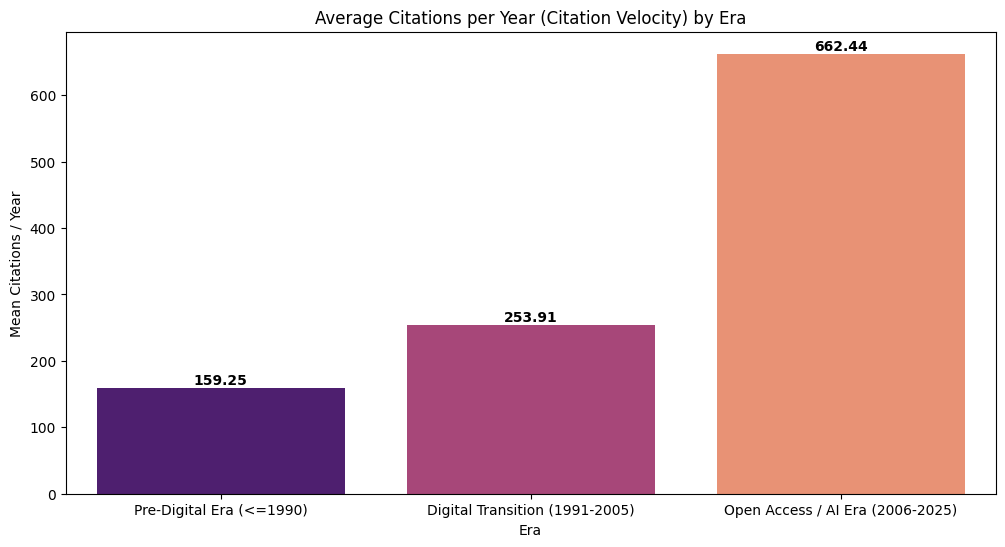

In [106]:
# 1. Calculate the age of the paper
current_year = 2025
# We add 1 to the denominator to avoid division by zero for 2025 papers
df['paper_age'] = current_year - df['publication_year'] + 1
df['citations_per_year'] = df['cited_by_count'] / df['paper_age']

# 2. Calculate Era Shares
total_citations = df['cited_by_count'].sum()
total_papers = len(df)

era_stats = df.groupby('era').agg(
    paper_count=('id', 'count'),
    total_era_citations=('cited_by_count', 'sum'),
    mean_citations_per_year=('citations_per_year', 'mean'),
    median_citations_per_year=('citations_per_year', 'median')
).reindex(era_order)

era_stats['percent_of_total_papers'] = (era_stats['paper_count'] / total_papers) * 100
era_stats['percent_of_total_citations'] = (era_stats['total_era_citations'] / total_citations) * 100

print("--- Era Impact Comparison ---")
print(era_stats[['percent_of_total_papers', 'percent_of_total_citations', 'mean_citations_per_year']])

# 3. Visualization: Citations per Year (The 'True' Impact)
plt.figure(figsize=(12, 6))
sns.barplot(x=era_stats.index, y=era_stats['mean_citations_per_year'], palette='magma')
plt.title('Average Citations per Year (Citation Velocity) by Era')
plt.ylabel('Mean Citations / Year')
plt.xlabel('Era')

for i, v in enumerate(era_stats['mean_citations_per_year']):
    plt.text(i, v + 5, f'{v:.2f}', ha='center', fontweight='bold')

plt.show()


##Evolution of Collaboration

/tmp/ipython-input-3571997427.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=collaboration_trends.index, y=collaboration_trends.values, palette='viridis')


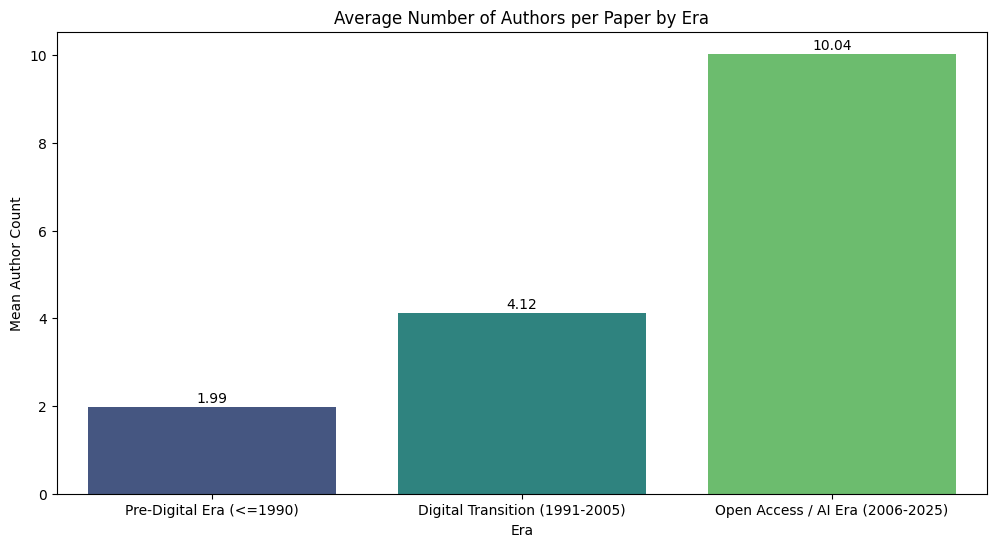

In [107]:
# 2. Evolution of Collaboration
# C alculate the number of authors for each paper

plt.figure(figsize=(12, 6))

# Plotting the average number of authors over time
collaboration_trends = df.groupby('era')['num_authors'].mean().reindex(era_order)

sns.barplot(x=collaboration_trends.index, y=collaboration_trends.values, palette='viridis')
plt.title('Average Number of Authors per Paper by Era')
plt.ylabel('Mean Author Count')
plt.xlabel('Era')

for i, v in enumerate(collaboration_trends.values):
    plt.text(i, v + 0.1, f'{v:.2f}', ha='center')

plt.show()

##Topic Analysis (Top Topics by Era)

/tmp/ipython-input-549144772.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=topic_diversity.index, y=topic_diversity.values, palette='viridis')


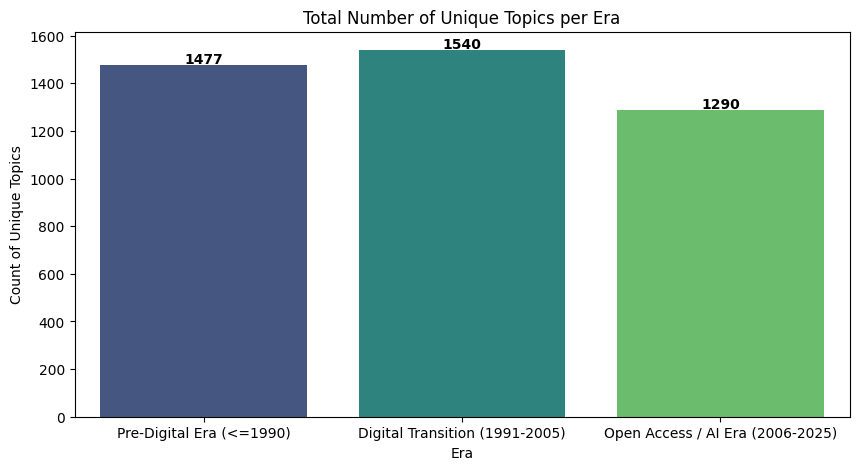

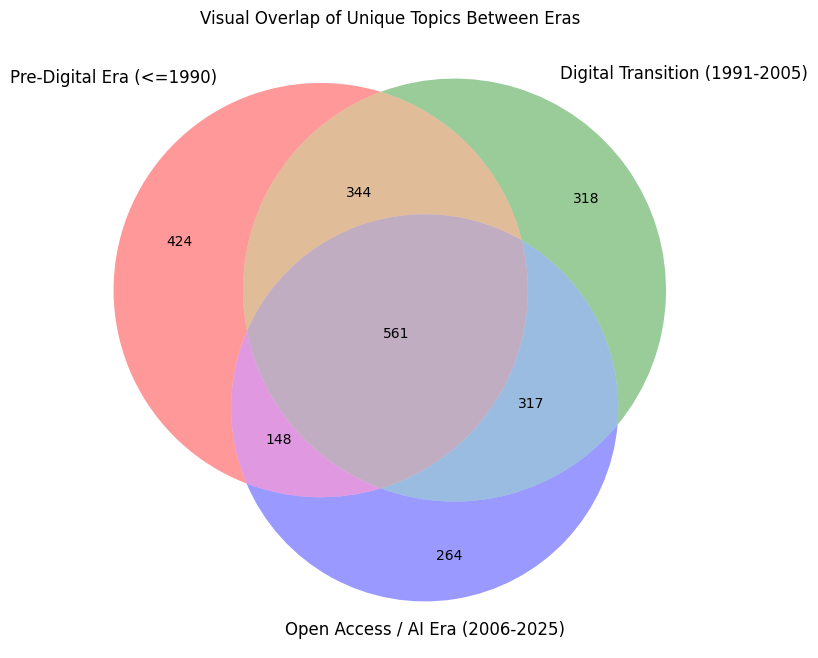

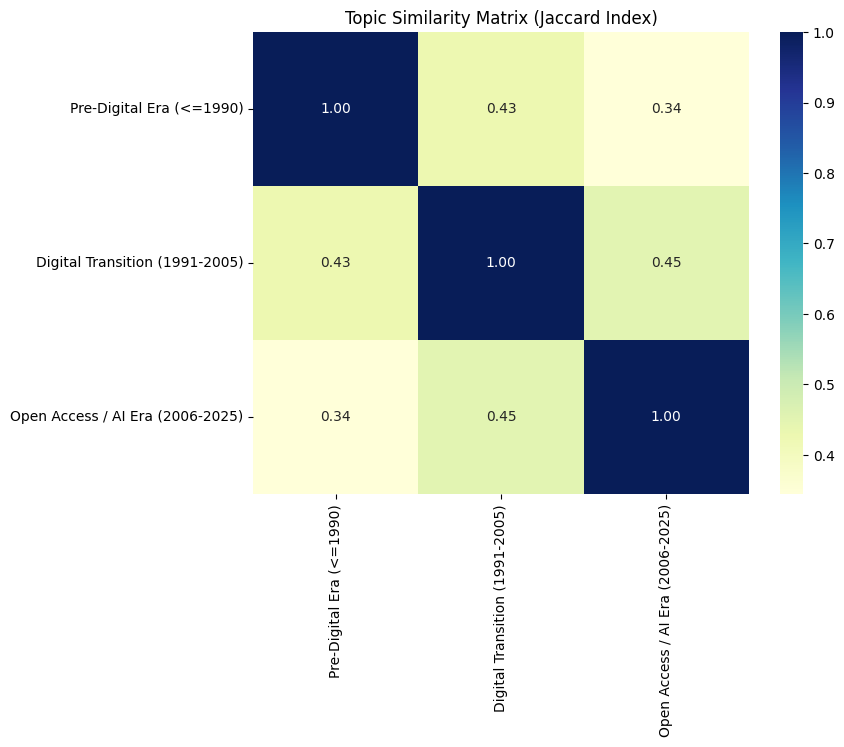

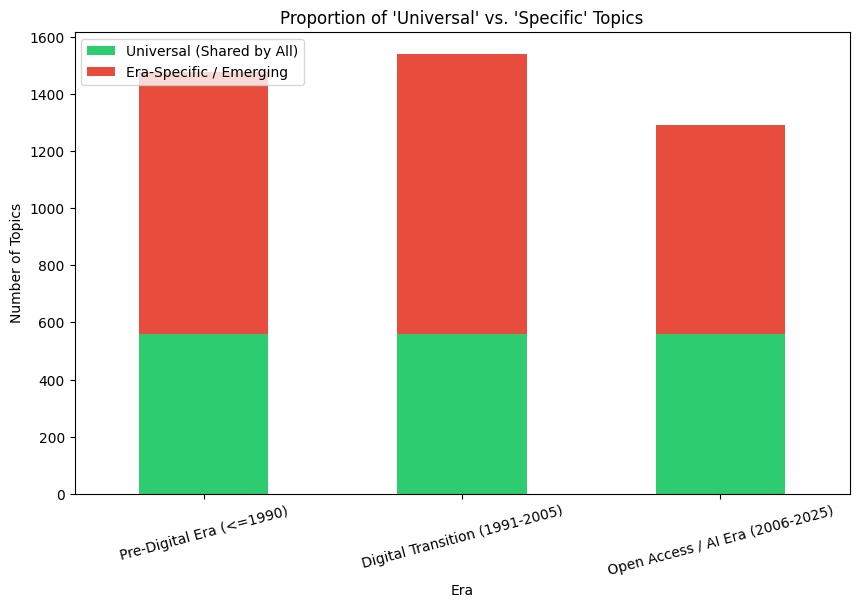

In [108]:
# --- 1. Topic Diversity: Number of Unique Topics per Era ---
plt.figure(figsize=(10, 5))
topic_diversity = df.groupby('era')['primary_topic'].nunique().reindex(era_order)

# We use a bar chart here as it clearly shows the 'amount' per category
sns.barplot(x=topic_diversity.index, y=topic_diversity.values, palette='viridis')
plt.title('Total Number of Unique Topics per Era')
plt.ylabel('Count of Unique Topics')
plt.xlabel('Era')

# Adding labels on top of bars
for i, v in enumerate(topic_diversity.values):
    plt.text(i, v + 5, str(v), ha='center', fontweight='bold')
plt.show()

# --- 2. Topic Overlap Preparation ---
# Getting unique topics per era as sets for comparison
topics_pre = set(df[df['era'] == era_order[0]]['primary_topic'].dropna().unique())
topics_trans = set(df[df['era'] == era_order[1]]['primary_topic'].dropna().unique())
topics_open = set(df[df['era'] == era_order[2]]['primary_topic'].dropna().unique())

# --- 3. Venn Diagram for Topic Intersection ---
if 'venn3' in globals():
    plt.figure(figsize=(10, 8))
    venn3([topics_pre, topics_trans, topics_open], set_labels=era_order)
    plt.title("Visual Overlap of Unique Topics Between Eras")
    plt.show()

# --- 4. Heatmap of Jaccard Similarity ---
# Measures the percentage of shared topics relative to the total topics in both sets
def calculate_jaccard(set1, set2):
    intersection = len(set1.intersection(set2))
    union = len(set1.union(set2))
    return intersection / union if union > 0 else 0

era_sets = [topics_pre, topics_trans, topics_open]
similarity_matrix = np.zeros((3, 3))

for i in range(3):
    for j in range(3):
        similarity_matrix[i][j] = calculate_jaccard(era_sets[i], era_sets[j])

plt.figure(figsize=(8, 6))
sns.heatmap(similarity_matrix, annot=True, xticklabels=era_order, yticklabels=era_order, cmap="YlGnBu", fmt=".2f")
plt.title("Topic Similarity Matrix (Jaccard Index)")
plt.show()

# --- 5. Shared vs. Unique Topic Proportion ---
# This shows how many topics survived through all eras vs how many are era-specific
shared_all = topics_pre.intersection(topics_trans).intersection(topics_open)

data = []
for name, t_set in zip(era_order, era_sets):
    shared = len(t_set.intersection(shared_all))
    unique = len(t_set) - shared
    data.append({'Era': name, 'Universal (Shared by All)': shared, 'Era-Specific / Emerging': unique})

df_overlap = pd.DataFrame(data).set_index('Era')
df_overlap.plot(kind='bar', stacked=True, figsize=(10, 6), color=['#2ecc71', '#e74c3c'])
plt.title("Proportion of 'Universal' vs. 'Specific' Topics")
plt.ylabel("Number of Topics")
plt.xticks(rotation=15)
plt.legend(loc='upper left')
plt.show()

##Relationship Between References and Citations

--- Spearman Rank Correlation (More Reliable) ---
Spearman Correlation for Pre-Digital Era (<=1990): 0.010
Spearman Correlation for Digital Transition (1991-2005): -0.054
Spearman Correlation for Open Access / AI Era (2006-2025): -0.108


/tmp/ipython-input-104902255.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned_impact = df.groupby(['era', 'ref_category'])['cited_by_count'].median().unstack().reindex(era_order)


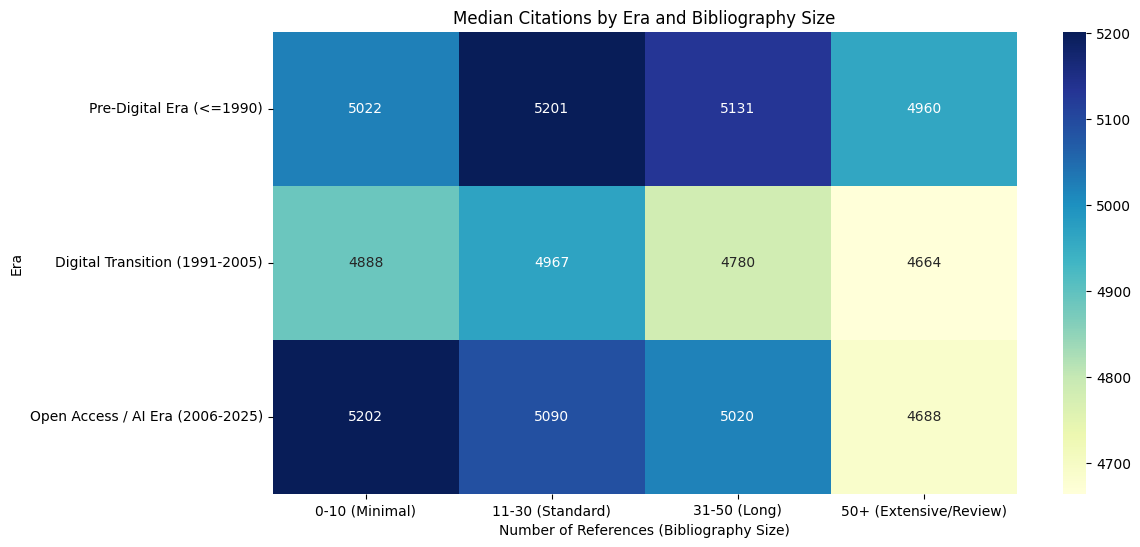

/tmp/ipython-input-104902255.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


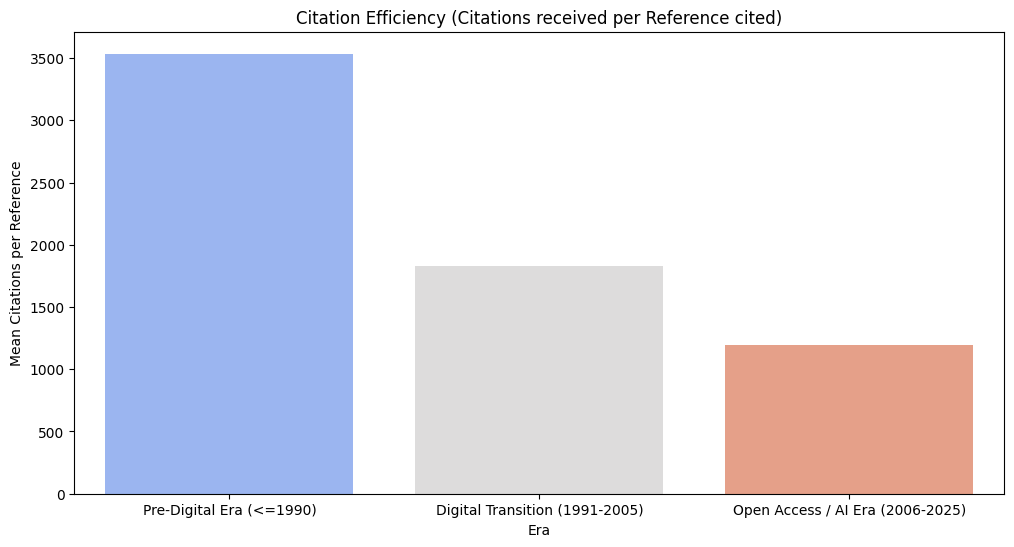

In [112]:
# 1. Spearman Correlation (Rank-based)
# Pearson correlation (what you used) fails with outliers.
# Spearman is much better for academic data as it measures if "higher X leads to higher Y" regardless of the scale.
print("--- Spearman Rank Correlation (More Reliable) ---")
for era in era_order:
    era_data = df[df['era'] == era]
    # Dropping rows with missing values for these columns if any
    clean_subset = era_data.dropna(subset=['references_count', 'cited_by_count'])
    spearman = clean_subset['references_count'].corr(clean_subset['cited_by_count'], method='spearman')
    print(f"Spearman Correlation for {era}: {spearman:.3f}")

# 2. Binned Analysis (The "Bibliography Strategy")
# Does having a very short vs. very long bibliography actually change the citation median?
def bin_references(count):
    if count <= 10: return '0-10 (Minimal)'
    if count <= 30: return '11-30 (Standard)'
    if count <= 50: return '31-50 (Long)'
    return '50+ (Extensive/Review)'

df['ref_category'] = df['references_count'].apply(bin_references)
ref_order = ['0-10 (Minimal)', '11-30 (Standard)', '31-50 (Long)', '50+ (Extensive/Review)']

# Calculate median citations per reference category and era
binned_impact = df.groupby(['era', 'ref_category'])['cited_by_count'].median().unstack().reindex(era_order)

# 3. Visualization: Heatmap of Median Citations
plt.figure(figsize=(12, 6))
sns.heatmap(binned_impact[ref_order], annot=True, fmt=".0f", cmap="YlGnBu")
plt.title('Median Citations by Era and Bibliography Size')
plt.ylabel('Era')
plt.xlabel('Number of References (Bibliography Size)')
plt.show()

# 4. Visualization: Impact Efficiency (Citations per Reference)
# This shows how "useful" each reference is in generating a citation
plt.figure(figsize=(12, 6))

sns.barplot(
    x='era',
    y='citation_efficiency',
    data=df,
    order=era_order,
    palette='coolwarm',
    errorbar=None  # This line removes the vertical lines at the top
)

plt.title('Citation Efficiency (Citations received per Reference cited)')
plt.ylabel('Mean Citations per Reference')
plt.xlabel('Era')
plt.show()

####Handling Dtype after adding new columns

In [110]:
# 1. Convert 'era' and 'ref_category' to categories (since they have a small number of repeating values)
df['era'] = df['era'].astype('category')
df['ref_category'] = df['ref_category'].astype('category')

# Display a sample to ensure data is still readable
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 14993 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   id                        14993 non-null  string  
 1   primary_topic             14993 non-null  category
 2   publication_year          14993 non-null  int64   
 3   source                    14993 non-null  category
 4   authorships               14993 non-null  string  
 5   language                  14993 non-null  category
 6   cited_by_count            14993 non-null  int64   
 7   references_count          14993 non-null  int64   
 8   institution               14993 non-null  category
 9   type                      14993 non-null  category
 10  cited_by_count_outlier    14993 non-null  int64   
 11  references_count_outlier  14993 non-null  int64   
 12  num_authors               14779 non-null  Int64   
 13  num_institutions          10728 non-null  Int64   


#save data frame to csv

In [111]:
def save_dataframe_to_csv(df: pd.DataFrame, output_path: str):
    """
    Saves a pandas DataFrame to a CSV file.

    Args:
        df (pd.DataFrame): The DataFrame to save.
        output_path (str): The file path where the CSV will be saved.
    """
    df.to_csv(output_path, index=False)
    print(f"DataFrame saved to {output_path}")


# Call function to save the final cleaned and transformed DataFrame
save_dataframe_to_csv(df, 'final_cleaned_data.csv')

DataFrame saved to final_cleaned_data.csv
